# FRAUD DETECTION

In [14]:
pip install numpy

Note: you may need to restart the kernel to use updated packages.


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd


In [16]:
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score,accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [17]:
df=pd.read_csv("\\Users\\VENKATESH\\Desktop\\pavanids\\creditcard1.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [18]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [20]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.759088e-12,-8.251210e-13,-9.655224e-13,8.321417e-13,1.650335e-13,4.248462e-13,-3.054652e-13,8.777941e-14,-1.179734e-12,...,-3.405795e-13,-5.723161e-13,-9.725925e-13,1.464150e-12,-6.987098e-13,-5.617860e-13,3.332081e-12,-3.518874e-12,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


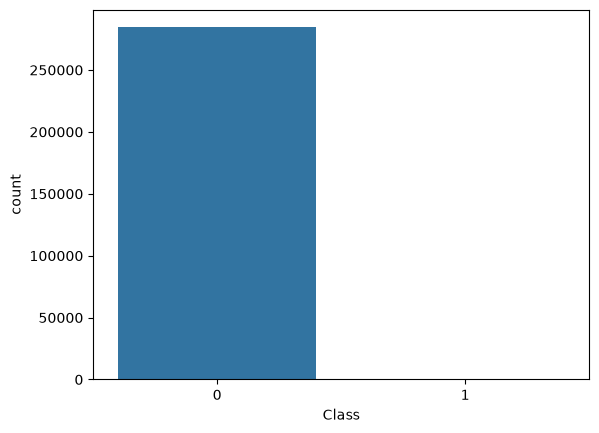

In [21]:
sns.countplot(x=df["Class"],data=df)
plt.show()

Class
0    284315
1       492
Name: count, dtype: int64


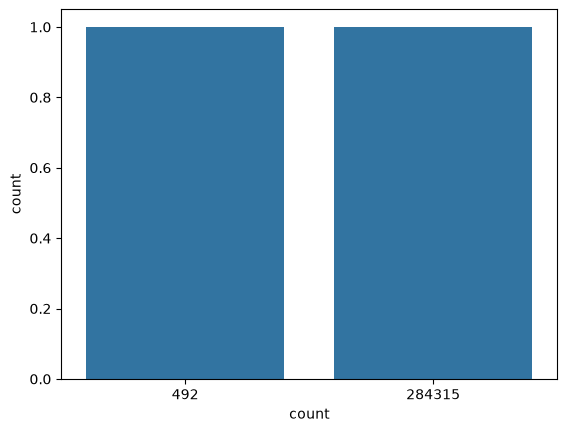

In [22]:
fraud_count=df["Class"].value_counts()
print(fraud_count)
sns.countplot(x=fraud_count,data=df)
plt.show()

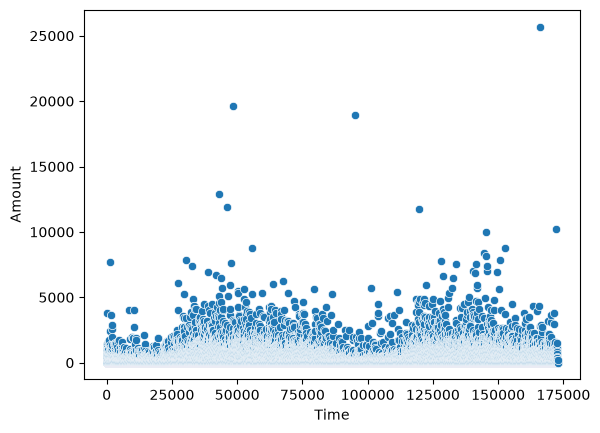

In [23]:
sns.scatterplot(x="Time",y="Amount",data=df)
plt.show()

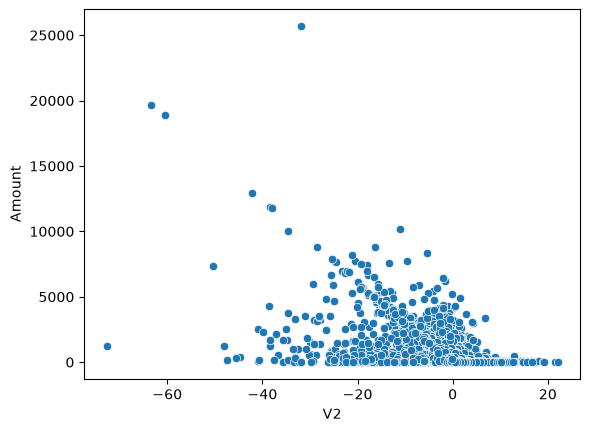

In [24]:
sns.scatterplot(x='V2',y='Amount',data=df)
plt.show()

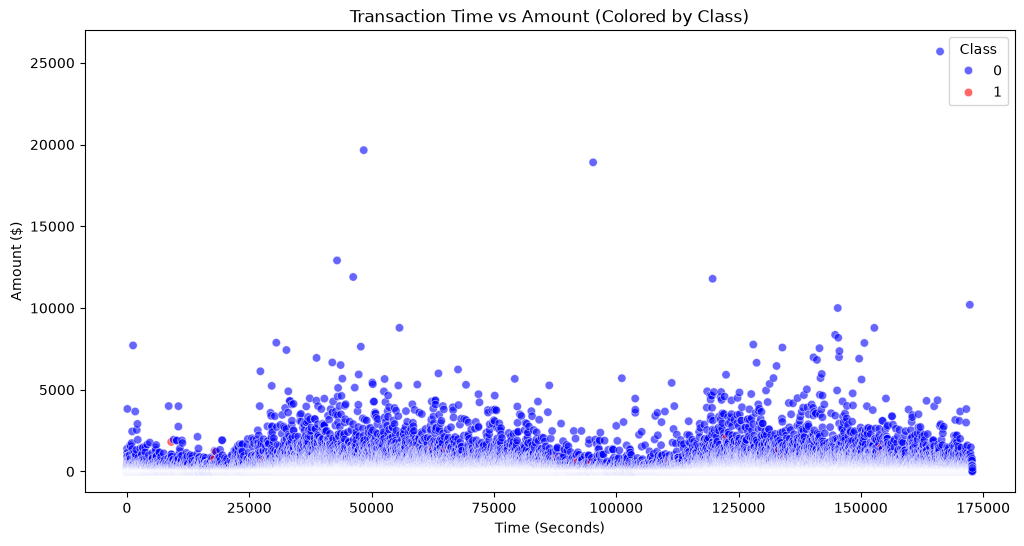

In [25]:
plt.figure(figsize=(12, 6))
sns.scatterplot(x='Time', y='Amount', hue='Class', data=df, alpha=0.6, palette=['blue', 'red'])
plt.title('Transaction Time vs Amount (Colored by Class)')
plt.xlabel('Time (Seconds)')
plt.ylabel('Amount ($)')
plt.show()

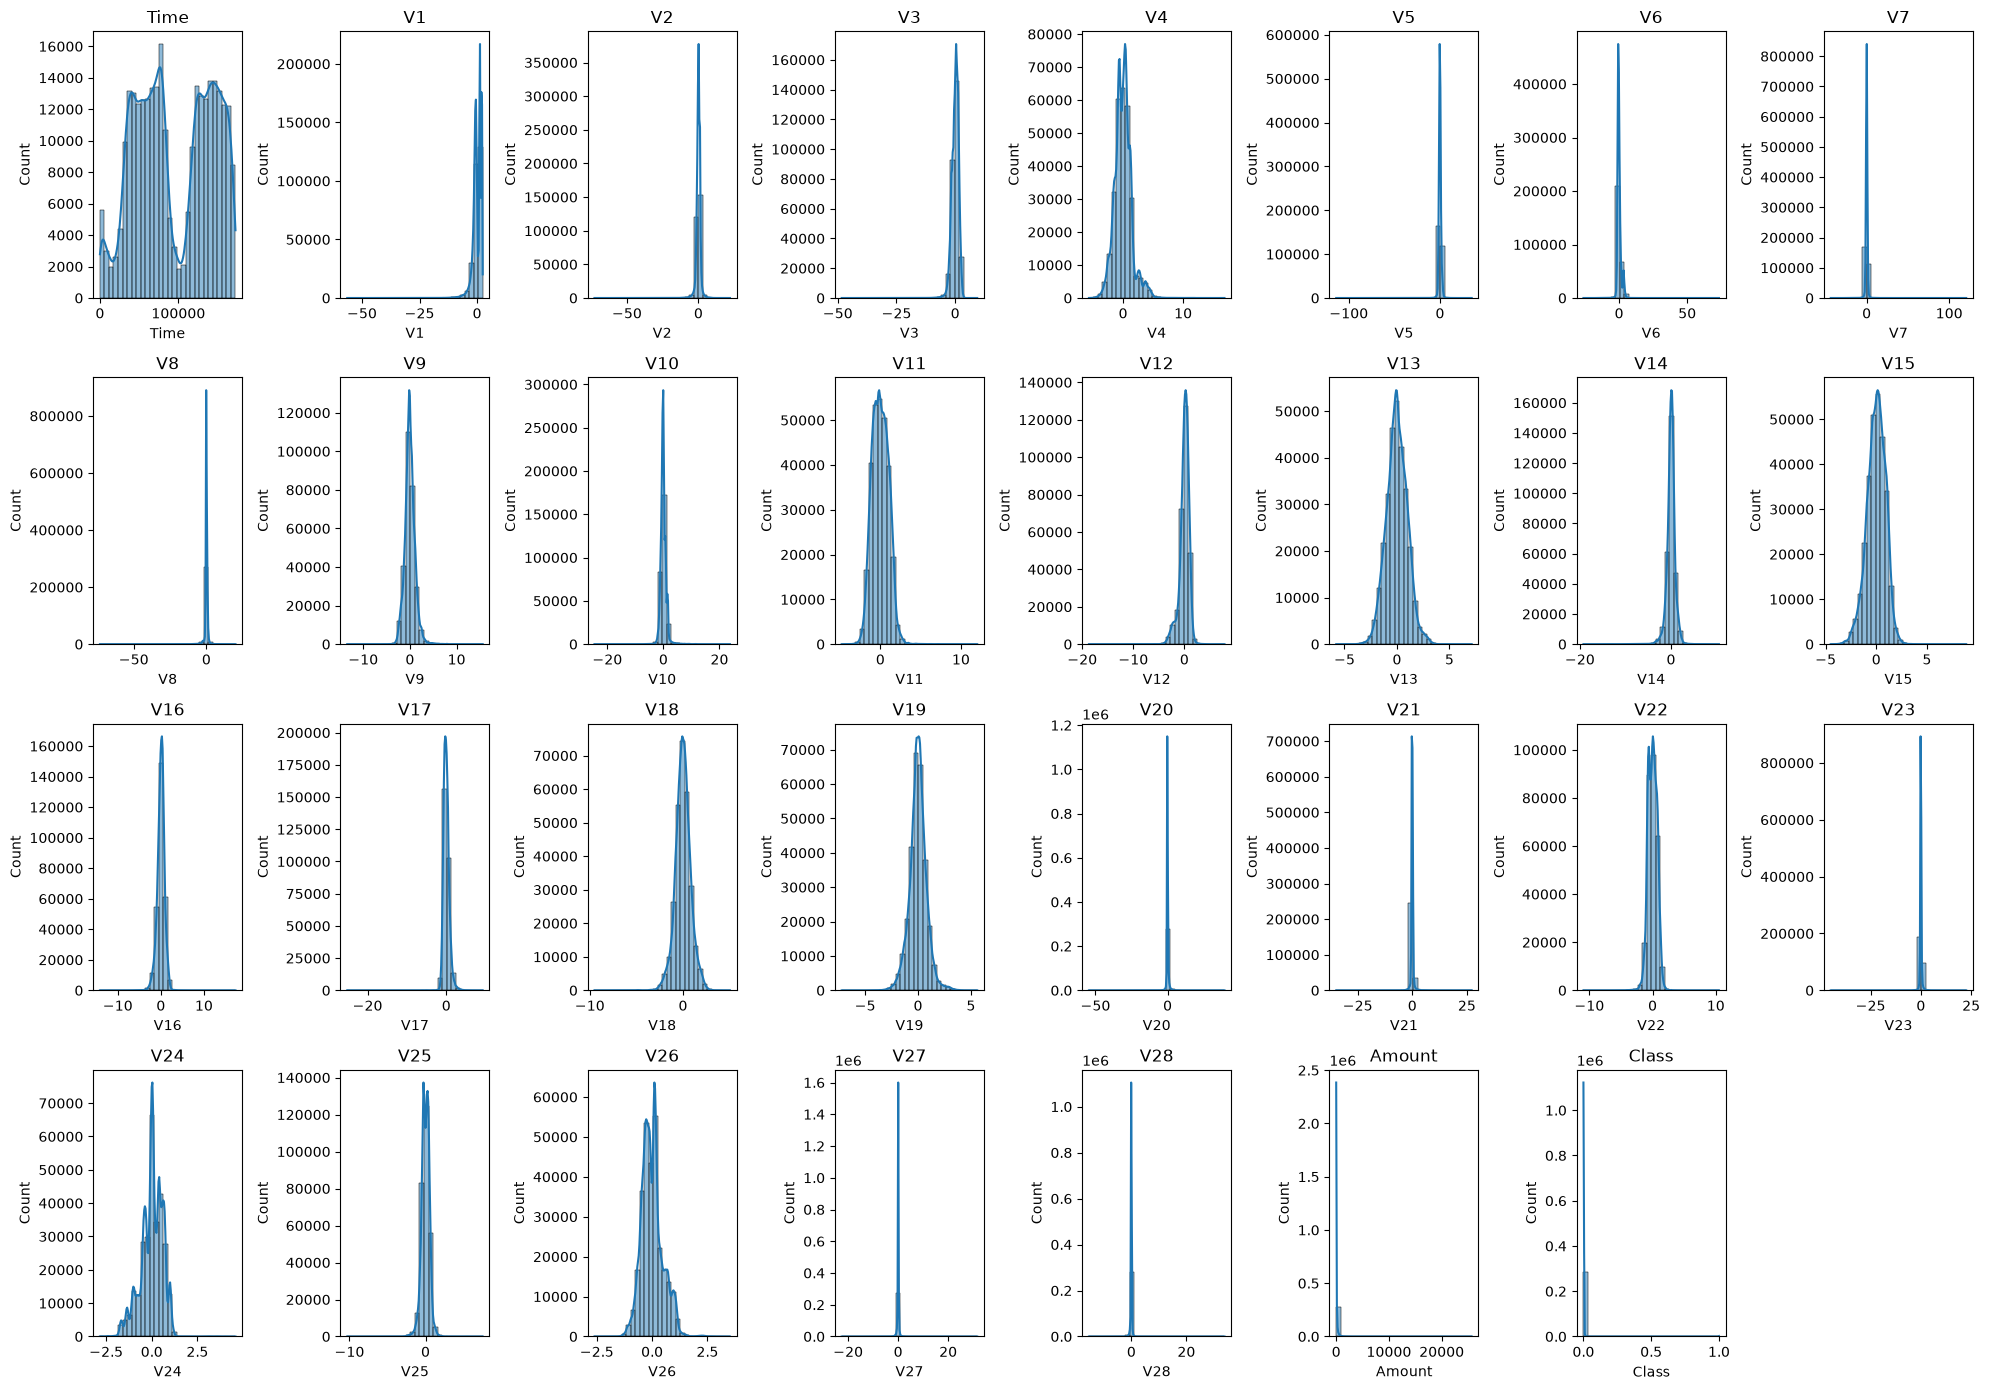

In [26]:
plt.figure(figsize=(20, 14))

for i, col in enumerate(df.loc[:, 'Time':'Class'].columns):
    plt.subplot(4,8, i+1)
    sns.histplot(df[col], bins=30, kde=True)
    plt.title(col)

plt.tight_layout()
plt.show()

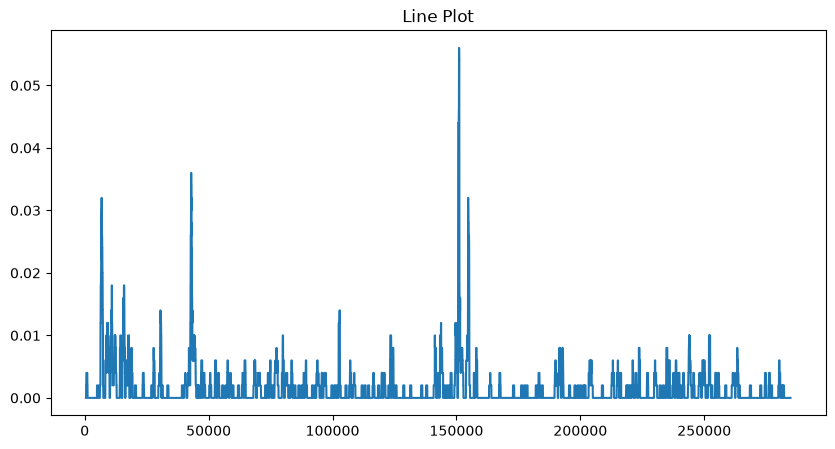

In [27]:


plt.figure(figsize=(10, 5))
df['Class'].rolling(window=500).mean().plot()
plt.title('Line Plot')
plt.show()

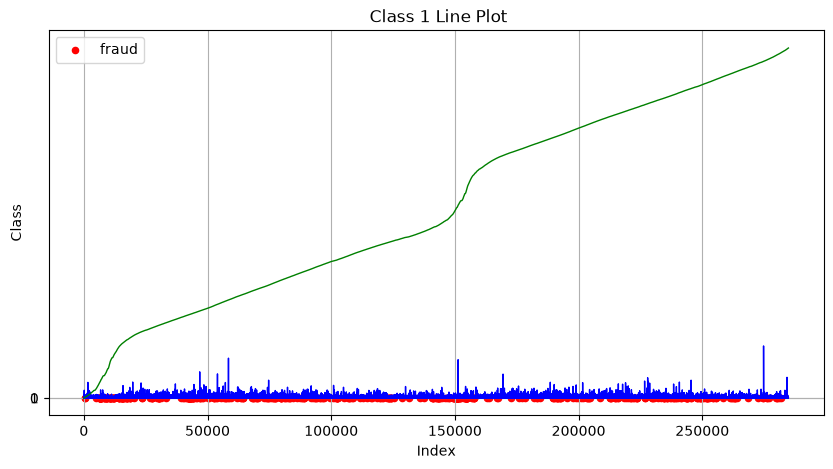

In [28]:
plt.figure(figsize=(10,5))

plt.plot(df.index, df['Amount'], color='blue', linewidth=1)
plt.plot(df.index, df['Time'], color='green', linewidth=1)

# Class 1 values ki red dots
plt.scatter(
    df.index[df['Class'] == 1],
    df['Class'][df['Class'] == 1],
    color='red',
    s=20,
    label='fraud'
)
plt.xlabel("Index")
plt.ylabel("Class")
plt.title(" Class 1 Line Plot")

plt.yticks([0,1])
plt.legend()
plt.grid()
plt.show()

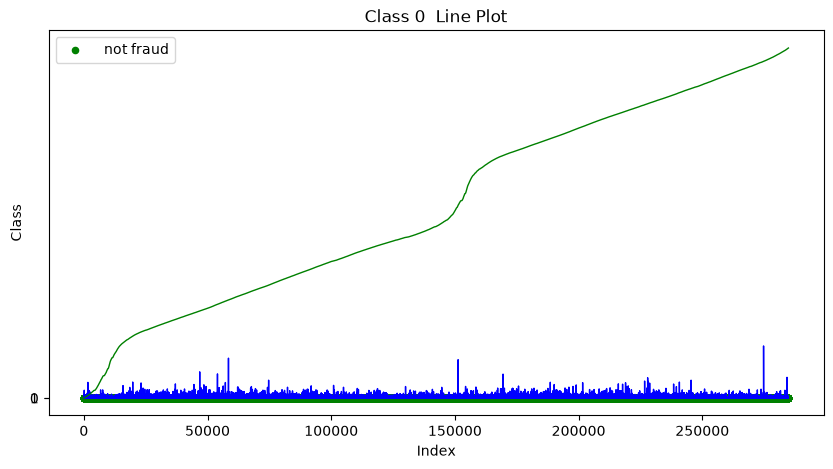

In [29]:
plt.figure(figsize=(10,5))

plt.plot(df.index, df['Amount'], color='blue', linewidth=1)
plt.plot(df.index, df['Time'], color='green', linewidth=1)

plt.scatter(
    df.index[df['Class'] == 0],
    df['Class'][df['Class'] == 0],
    color='green',
    s=20,
    label=' not fraud'
)
plt.xlabel("Index")
plt.ylabel("Class")
plt.title("Class 0  Line Plot")

plt.yticks([0,1])
plt.legend()

In [30]:
x=df.drop('Class',axis=1)
y=df['Class']

In [31]:
#train test split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((227845, 30), (56962, 30), (227845,), (56962,))

In [32]:
#scaler amount and time
scaler=StandardScaler()
x_train[['Amount','Time']]=scaler.fit_transform(x_train[['Amount','Time']])
x_test[['Amount','Time']]=scaler.fit_transform(x_test[['Amount','Time']])

In [33]:
#count class labels
neg_count=(y_train==0).sum()
pos_count=(y_train==1).sum()
print('neg:',neg_count)
print('pos:',pos_count)

neg: 227451
pos: 394


In [34]:
 #Train the Model 
# class_weight='balanced' helps the model pay extra attention to the minority fraud class
rf_model = RandomForestClassifier(
    n_estimators=200, 
    class_weight='balanced', 
    random_state=42, 
    n_jobs=-1
)
rf_model.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [36]:
 #Make Predictions & Evaluate
y_pred_rf =rf_model.predict(x_test)
y_pred_rf


array([1, 0, 0, ..., 0, 0, 0], shape=(56962,))

In [37]:
y_prob_rf = rf_model.predict_proba(x_test)[:, 1]
y_prob_rf

array([0.93, 0.  , 0.  , ..., 0.01, 0.  , 0.  ], shape=(56962,))

In [38]:
x_training=rf_model.score(x_train,y_train)
y_testing=rf_model.score(x_test,y_test)
print("x_training:",x_training)
print("y_testing:",y_testing)

x_training: 0.9999604994623538
y_testing: 0.9995786664794073


In [39]:
#model accuracy
rf_accuracy=accuracy_score(y_test,y_pred_rf)
rf_accuracy

0.9995786664794073

In [40]:

print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_rf):.4f}")

[[56860     4]
 [   20    78]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.95      0.80      0.87        98

    accuracy                           1.00     56962
   macro avg       0.98      0.90      0.93     56962
weighted avg       1.00      1.00      1.00     56962

ROC-AUC Score: 0.9813


In [42]:
#Initialize XGBoost Classifier
scale_weight=len(y_train[y_train==0])/len(y_train[y_train==1])
xgb_model = xgb.XGBClassifier(scale_pos_weight=scale_weight, random_state=42)
xgb_model.fit(x_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [45]:
#Predictions & Evaluation
y_pred_xgb = xgb_model.predict(x_test)
y_pred_proba_xgb =xgb_model.predict_proba(x_test)[:, 1]
print("y_pred_xgb:",y_pred_xgb)
print("y_pred_proba_xgb:",y_pred_proba_xgb)


y_pred_xgb: [1 0 0 ... 0 0 0]
y_pred_proba_xgb: [9.9999893e-01 1.4626393e-07 4.9472446e-06 ... 5.5022665e-06 9.7843383e-07
 4.3670093e-06]


In [46]:
print(confusion_matrix(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))
print("\nROC-AUC Score:", roc_auc_score(y_test, y_pred_proba_xgb))

[[56860     4]
 [   17    81]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.95      0.83      0.89        98

    accuracy                           1.00     56962
   macro avg       0.98      0.91      0.94     56962
weighted avg       1.00      1.00      1.00     56962


ROC-AUC Score: 0.9829469597349352


In [47]:
xgb_accuracy=accuracy_score(y_test,y_pred_xgb)
xgb_accuracy

0.9996313331694814

In [48]:
#train the model
import lightgbm as lgb
#Initialize LightGBM
lgb_model = lgb.LGBMClassifier(
    n_estimators=200,
    scale_pos_weight=scale_weight, 
    random_state=42,
    n_jobs=-1
)
lgb_model.fit(x_train, y_train)

[LightGBM] [Info] Number of positive: 394, number of negative: 227451
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.016127 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 7650
[LightGBM] [Info] Number of data points in the train set: 227845, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.001729 -> initscore=-6.358339
[LightGBM] [Info] Start training from score -6.358339
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gai

,n_estimators,200
,random_state,42
,n_jobs,-1
,scale_pos_weight,577.2868020304569
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,subsample_for_bin,200000
,objective,None
,class_weight,None


In [49]:
print("LGBM Train Accuracy:", lgb_model.score(x_train, y_train))
print("LGBM Test Accuracy :", lgb_model.score(x_test, y_test))

LGBM Train Accuracy: 0.9762952884636485
LGBM Test Accuracy : 0.9741406551736245


In [50]:
#Evaluation
y_pred_lgb = lgb_model.predict(x_test)
y_prob_lgb = lgb_model.predict_proba(x_test)[:, 1]
print("y_pred_lgb:",y_pred_lgb)
print("y_prob_lgb:",y_prob_lgb )

y_pred_lgb: [1 0 0 ... 0 0 0]
y_prob_lgb: [1. 0. 0. ... 0. 0. 0.]


In [51]:
print(confusion_matrix(y_test, y_pred_lgb))
print(classification_report(y_test, y_pred_lgb))
print("\nROC-AUC Score:", roc_auc_score(y_test,y_prob_lgb))

[[55405  1459]
 [   14    84]]
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56864
           1       0.05      0.86      0.10        98

    accuracy                           0.97     56962
   macro avg       0.53      0.92      0.54     56962
weighted avg       1.00      0.97      0.99     56962


ROC-AUC Score: 0.9157023776027011


In [52]:
lgb_accuracy=accuracy_score(y_test,y_pred_lgb)
lgb_accuracy

0.9741406551736245

In [53]:
from catboost import CatBoostClassifier
#Initialize CatBoost
cat_model = CatBoostClassifier(
    iterations=300,
    scale_pos_weight=scale_weight, # Imbalance handling
    random_seed=42,
    thread_count=-1,               # n_jobs=-1 ki badhulu CatBoost lo thread_count vadali
    verbose=100                    # Prathi 100 iterations ki progress print chestundi
)
cat_model.fit(x_train, y_train)

Learning rate set to 0.315592
0:	learn: 0.3104160	total: 213ms	remaining: 1m 3s
100:	learn: 0.0010850	total: 5.86s	remaining: 11.5s
200:	learn: 0.0009422	total: 9.72s	remaining: 4.79s
299:	learn: 0.0009410	total: 13.4s	remaining: 0us


CatBoostClassifier(iterations=300, random_seed=42, scale_pos_weight=577.2868020304569, verbose=100)

In [54]:
print("\nCatBoost Train Accuracy:", cat_model.score(x_train, y_train))
print("CatBoost Test Accuracy :", cat_model.score(x_test, y_test))



CatBoost Train Accuracy: 0.9998463867980425
CatBoost Test Accuracy : 0.999385555282469


In [55]:
# 4. Evaluation
y_pred_cat = cat_model.predict(x_test)
y_prob_cat = cat_model.predict_proba(x_test)[:, 1]
print("y_pred_cat:",y_pred_cat)
print("y_prob_cat:",y_prob_cat)


y_pred_cat: [1 0 0 ... 0 0 0]
y_prob_cat: [9.99993015e-01 7.61591748e-09 2.92246848e-08 ... 2.92462448e-07
 2.20523382e-04 4.36526761e-05]


In [56]:
print(confusion_matrix(y_test, y_pred_cat))
print("\n--- CatBoost Classification Report ---")
print(classification_report(y_test, y_pred_cat))
print("CatBoost ROC-AUC:", roc_auc_score(y_test, y_prob_cat))

[[56848    16]
 [   19    79]]

--- CatBoost Classification Report ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.83      0.81      0.82        98

    accuracy                           1.00     56962
   macro avg       0.92      0.90      0.91     56962
weighted avg       1.00      1.00      1.00     56962

CatBoost ROC-AUC: 0.9639530193056401


In [57]:
cat_accuracy=accuracy_score(y_test,y_pred_cat)
cat_accuracy

0.999385555282469

In [58]:
print("rf_accuracy:",rf_accuracy)
print("xgb_accuracy:",xgb_accuracy)
print("lgb_accuracy:",lgb_accuracy)
print("cat_accuracy:",cat_accuracy)

rf_accuracy: 0.9995786664794073
xgb_accuracy: 0.9996313331694814
lgb_accuracy: 0.9741406551736245
cat_accuracy: 0.999385555282469


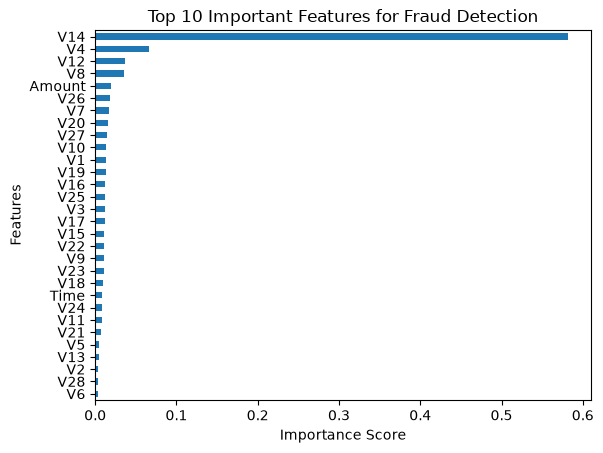

In [59]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Model nundi feature importances extract 

importances =xgb_model.feature_importances_
feature = pd.Series( importances,index=x.columns)
feature.sort_values().plot(kind='barh')
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Top 10 Important Features for Fraud Detection")
plt.show()

In [61]:
from sklearn.model_selection import cross_val_score
scores=cross_val_score(xgb_model,x,y,cv=5)
print("Accuracy:",scores.mean())

Accuracy: 0.9989817690037477


In [62]:
#new data
sample=x_test.iloc[[2]]
prediction=xgb_model.predict(sample)
probability=xgb_model.predict_proba(sample)
if prediction[0]==0:
    print("prediction: nofraud transaction")
else:
    print("prediction: fraud transaction")
print("probability:",probability)   

prediction: nofraud transaction
probability: [[9.9999505e-01 4.9472446e-06]]
